# Single Distribution Center Solution with MIP Gap

The **single_dc_solve.ipynb** notebook solves for the optimal solution but takes a considerable amount of time.  This notebook solves the same model, but passes a parameter to the solver to allow it to terminate once it determines it is within a certain upper bound of the optimal solution.  This upper bound being referred to as the MIP Gap.

In [7]:
import pandas as pd
import pyomo.environ as pe
import numpy as np
import re
from plotly.offline import init_notebook_mode, iplot
import plotly.graph_objs as go
init_notebook_mode(connected=True)

import model_utils as utils

This is the same model generation call as is found in **single_dc_solve.ipynb**.

In [2]:
model = utils.gen_model(True)

The below cell creates a solver object and solves the model.  Note that a dictionary is being passed to the options parameter of the solver.  The Cbc interprets the `ratioGap` as an allowable tolerance away from the optimal solution to allow for early termination.  In this case 0.01 should be interprested as 1%.  

In [3]:
solver = pe.SolverFactory('cbc', options = {'ratioGap': 0.01})
results = solver.solve(model, tee=True)

Welcome to the CBC MILP Solver 
Version: 2.10.7 
Build Date: Feb 14 2022 

command line - /usr/bin/cbc -ratioGap 0.01 -printingOptions all -import /tmp/tmphkyzu3hs.pyomo.lp -stat=1 -solve -solu /tmp/tmphkyzu3hs.pyomo.soln (default strategy 1)
ratioGap was changed from 0 to 0.01
Option for printingOptions changed from normal to all
Presolve 3601 (-119) rows, 6666 (-714) columns and 25434 (-2856) elements
Statistics for presolved model
Original problem has 1230 integers (1230 of which binary)
Presolved problem has 1230 integers (1230 of which binary)
==== 1230 zero objective 5437 different
==== absolute objective values 5437 different
==== for integers 1230 zero objective 1 different
1230 variables have objective of 0
==== for integers absolute objective values 1 different
1230 variables have objective of 0
===== end objective counts


Problem has 3601 rows, 6666 columns (5436 with objective) and 25434 elements
Column breakdown:
5436 of type 0.0->inf, 0 of type 0.0->up, 0 of type lo->inf

Note how the solver now exists with a run time under 1 second.  It has identified a solution that yields a total cost of \\$7,528.81 and knows a lower bound for the optimal value to be \\$7,474.03.  This difference satisfying the 1% allowable tolerance.

## Cbc Output Review

The below section reviews the output of the Cbc solver when calculating without the MIP Gap set.  The data shows that a high quality solution can be obtained relatively quickly, within a couple seconds.  Meanwhile, the guaranteed optimal solution requires a significantly longer wait to achive.

In [4]:
full_line_regex = re.compile("^(Cbc).+\(\d+\.\d+ seconds\)")
best_soln_regex = re.compile(r"(\d+\.\d+) best solution")
best_possible_regex = re.compile(r"best possible (\d+\.\d+)")
time_regex = re.compile(r"(\d+.\d+) seconds")

best_solns = []
best_possible_solns = []
solve_times = []

solve_dets = []

with open('cbc_output.txt', 'r') as file:
    for line in file:
        if not full_line_regex.match(line):
            continue
        if not best_soln_regex.search(line):
            continue
        best_soln_match = best_soln_regex.search(line)
        best_soln = float(best_soln_match.group(1))
        best_poss_match = best_possible_regex.search(line)
        best_poss = float(best_poss_match.group(1))
        time_match = time_regex.search(line)
        time = float(time_match.group(1))

        solve_dets.append({
            'time': time,
            'best_soln': best_soln,
            'best_possible_soln': best_poss
        })

df = pd.DataFrame(solve_dets)
df['percent_diff'] = ((df['best_soln'] - df['best_possible_soln'])/df['best_possible_soln'])*100
df

,time,best_soln,best_possible_soln,percent_diff
0,0.59,7611.9032,7474.0316,1.844675
1,1.57,7528.8115,7474.0316,0.732936
2,1.87,7528.8115,7474.0316,0.732936
3,2.26,7528.8115,7474.0316,0.732936
4,3.40,7528.8115,7474.0316,0.732936
...,...,...,...,...
443,556.76,7481.5330,7481.1270,0.005427
444,557.37,7481.5330,7481.1955,0.004511
445,557.89,7481.5330,7481.2744,0.003457
446,558.26,7481.5330,7481.2744,0.003457


In [5]:
OPTIMAL_OBJ_VALUE = 7481.53302247
optimal_obj_array = np.ones(df.shape[0])*OPTIMAL_OBJ_VALUE

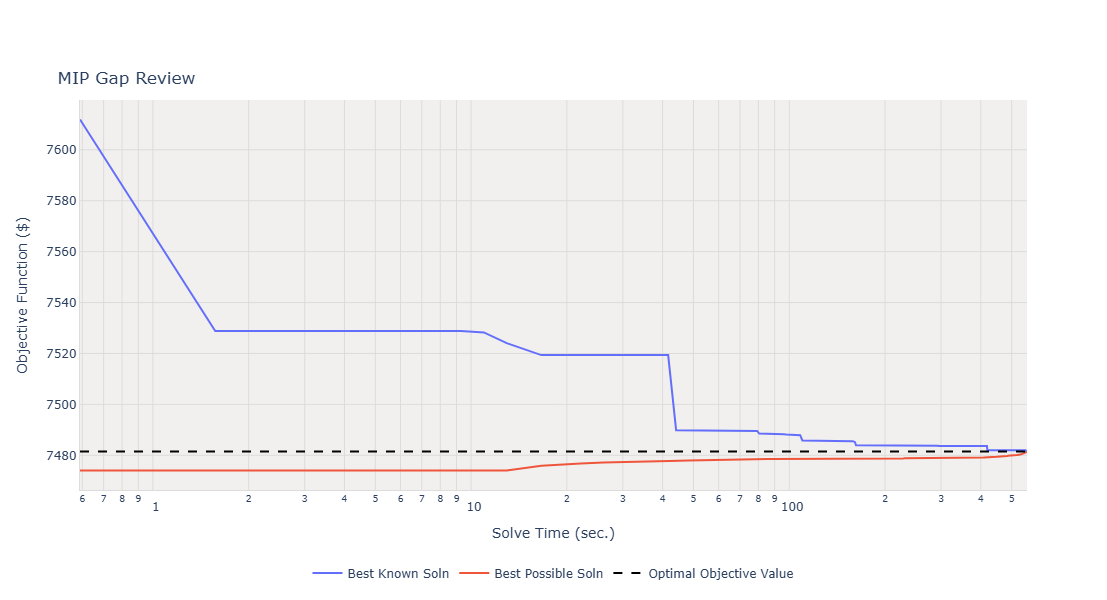

In [8]:
best_soln_trace = go.Scatter(
    x=df['time'],
    y=df['best_soln'],
    name='Best Known Soln',
    customdata=df['percent_diff'],
    hovertemplate='Best Known Soln: $%{y:,.2f}  (%{customdata:.2f}% gap)<extra></extra>'
)

best_poss_soln_trace = go.Scatter(
    x=df['time'],
    y=df['best_possible_soln'],
    name='Best Possible Soln',
    hovertemplate='Best Possible Soln: $%{y:,.2f}<extra></extra>'
)

optimal_obj_val_trace = go.Scatter(
    x=df['time'],
    y=optimal_obj_array,
    name='Optimal Objective Value',
    line={'dash': 'dash', 'color': 'black'},
    hovertemplate='Optimal Value: $%{y:,.2f}<extra></extra>'
)

grid_color='#DCDCDC'

layout={
    'title': {'text': 'MIP Gap Review',
             'x':0.052,
             'y':0.88,
             'xanchor':'left',
             'yanchor': 'top'},
    'height': 600,
    'xaxis': {
        'title': 'Solve Time (sec.)',
        'type':'log',
        'linecolor':grid_color,
        'gridcolor':grid_color,
        'showline':True
    },
    'yaxis': {
        'title': 'Objective Function ($)',
        'linecolor':grid_color,
        'gridcolor':grid_color,
        'showline':True
    },
    'plot_bgcolor': '#F2F0EF',
    'paper_bgcolor': 'rgb(255,255,255)',
    'legend': {
        'orientation': 'h',
        'xanchor': 'center',
        'yanchor': 'bottom',
        'x': 0.5,
        'y': -0.25
    },
    'hovermode': 'x unified'
}

fig = go.Figure(data=[best_soln_trace, best_poss_soln_trace, optimal_obj_val_trace], layout=layout)
iplot(fig)